# Map helper selection over the load sweep, campaign v3: R4, R4.1, R4.2, R5, R6

**Question.** The round-4 analysis (`paper_notes/round4/HANDOFF_RESULTS_V2.md`) found that on the curve Kuo's
helper often decodes copy 1 but has a building between it and the tail (38-58 % of packets on the W route), and
that a better-placed member exists in 25-39 % of packets. Kuo's selector (`--helperSelect=kuo`) sees distance
only. The simulator already has the same objective with the building map and the CAM positions
(`--helperSelect=map`, H3 in `LOCAL_H_ANALYSIS.md`): a building on a segment counts as NLOS, another vehicle as
NLOSv. This notebook is the v3 version of `MAP_HELPER_RESULTS.ipynb` (v2 data, 2026-11-01): the same analysis on campaign v3, which sends SCI 1-A on every PSSCH (`--sciOnEveryTx=true`) and puts the leader's aperiodic traffic on dynamic grants. It re-runs the five helper arms with `map` and asks, per scenario, traffic and load:

1. Does `map` beat `kuo` for the same arm (paired by seed)?
2. How do the gains of the helper arms over the leader-only schemes change when the helper is chosen with `map`?
3. What does it cost (spectrum per delivered packet), and does it change the disconnection time?
4. Which members does `map` pick, and how often does its helper miss copy 1?

| code | name | HARQ | helper |
|---|---|---|---|
| R1 / R2 / R3 | Blind / Opt 1 / Opt 2 | leader only | none (baselines, from v3) |
| R4 | Kuo | blind relay | `kuo` (v3) or `map` (v3_map) |
| R4.1 / R4.2 | NoTk-1 / NoTk-2 | Option 1 / 2, no takeover | `kuo` or `map` |
| R5 / R6 | Coop-1 / Coop | Option 1 / 2, NACK takeover + leader fallback | `kuo` or `map` |

**Cells:** highway, roundabout W (`rbt`), roundabout E (`rbtE`; roundabouts: curve window only) x periodic1tb /
aperiodic1tb x 0 / 15 / 30 / 45 / 60 background vehicles at 1.67 flows per car, IVD 30 m, 10 seeds.

**Data** (campaign v3, commit `32e29dd`, ease-rtx; after the stale-NDI fix):

| folder in `out/` | arms | loads | origin |
|---|---|---|---|
| `remote_v3` | R1-R3, Kuo R4, R4.1, R4.2, R5, R6 | 0, 15, 30, 45, 60 | campaign v3 (3000 runs) |
| `remote_v3_map` | map R4, R4.1, R4.2, R5, R6 | 0, 15, 30, 45, 60 | campaign v3, map arms (1500 runs) |

Every arm has every load, so no fill campaign is needed.

**Pairing.** Every map run has the same command as the Kuo run of the same cell and seed except
`--helperSelect` (checked in section 1), on the same machine, so map and Kuo see the same traces and the same
random streams up to the first different helper choice. Differences are paired by seed: mean difference and
95 % Student-t CI over the 10 seeds; *better* / *worse* only when the CI excludes 0.

## 0. Producing the data

Both folders were produced on ease-rtx at commit `32e29dd` (campaign v3, then its map arms as `out/v3_map`,
finished 2026-11-13, 1500 runs, 0 failed) and copied to the laptop as `out/remote_v3` and `out/remote_v3_map`.
Nothing in this notebook connects to the remote. Copy-back command for the map arms (from `harq_helper_study/`):
```
rsync -av -e "ssh -F $HOME/.ssh/ease-config" --prune-empty-dirs --include='*/' --include='COMMIT' \
  --include='*.cmd.json' --include='*_run.csv*' --include='*_member.csv*' --include='*_pkt.csv*' \
  --include='*_ltx.csv*' --include='*_htx.csv*' --include='*_hsel.csv*' --include='*_nack.csv*' \
  --include='*_grants.csv*' --exclude='*' \
  "ease-rtx:Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study/out/v3_map/" \
  "out/remote_v3_map/"
```
The per-run metrics are cached in `out/map_analysis_cache/remote_v3_map/` (recomputed when a folder's run count
changes).

In [1]:
import glob, json, os, re, subprocess, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

HERE = os.environ.get('MAP_NB_HERE',
                      '/Users/hadih/Documents/groupcast-adaptation-ns3/scratch_overlay/platoon_harq_robustness_eval/harq_helper_study')
OUT = os.path.join(HERE, 'out')
MAP_DIR = os.environ.get('MAP_DIR', 'remote_v3_map')            # folders relative to OUT
BASE_DIR = os.environ.get('MAP_BASE_DIR', 'remote_v3')         # leader arms and Kuo helper arms, all loads
CACHE = os.path.join(OUT, 'map_analysis_cache', os.path.basename(MAP_DIR))
sys.path.insert(0, os.path.join(HERE, 'paper_v2', 'analysis'))
import paper_data as pdm   # run_metrics(): the paper's per-run metrics (KPI window, roundabouts: curve only)

pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
HELPER_ARMS = ['R4', 'R4.1', 'R4.2', 'R5', 'R6']
LEADER_ARMS = ['R1', 'R2', 'R3']
NAME = {'R1': 'Blind', 'R2': 'Opt 1', 'R3': 'Opt 2', 'R4': 'Kuo', 'R4.1': 'NoTk-1', 'R4.2': 'NoTk-2',
        'R5': 'Coop-1', 'R6': 'Coop'}
# same hues as STUDY_RESULTS_remote_full.ipynb
COL = {'R1': '#2a78d6', 'R2': '#eb6834', 'R3': '#1baf7a', 'R4': '#eda100', 'R4.1': '#e87ba4',
       'R4.2': '#008300', 'R5': '#4a3aa7', 'R6': '#e34948'}
SCENS = ['hwy', 'rbt', 'rbtE']
SCEN_NAME = {'hwy': 'highway', 'rbt': 'roundabout W', 'rbtE': 'roundabout E'}
TRAFS = ['periodic1tb', 'aperiodic1tb']
NBGS = [0, 15, 30, 45, 60]
KEYS = ['sc', 'tr', 'nbg']
# (folder in OUT, arm folder, arm, selector)
SOURCES = ([(BASE_DIR, a, a, 'leader') for a in LEADER_ARMS]
           + [(BASE_DIR, a, a, 'kuo') for a in HELPER_ARMS]
           + [(MAP_DIR, a + '_map', a, 'map') for a in HELPER_ARMS])
for d in sorted({s[0] for s in SOURCES}):
    p = os.path.join(OUT, d)
    print(f'{d:22} {"present" if os.path.isdir(p) else "MISSING"}')

remote_v3              present
remote_v3_map          present


## 1. Integrity and pairing checks
* every folder's `COMMIT` contains `stale-ndi-fix` (never mix pre-fix and post-fix data);
* 10 seeds in every (arm, selector, scenario, traffic, load) cell;
* the run CSV says `helper_select = map` for every map run and `kuo` for every Kuo run;
* **pairing:** every map run's command equals the Kuo run's command of the same cell and seed, except
  `--helperSelect` and `--out` (binary path and repository root normalised). The curve window
  (`--kpiStart`, `--maxTime`) is included: it comes from the trace, so equality also shows that the traces are
  the same.

In [2]:
def prefixes(folder, armdir):
    d = os.path.join(OUT, folder, armdir)
    fs = glob.glob(d + '/*_run.csv') + glob.glob(d + '/*_run.csv.gz')
    return sorted({re.sub(r'_run\.csv(\.gz)?$', '', f) for f in fs})

def has_fix(folder):
    p = os.path.join(OUT, folder, 'COMMIT')
    if not os.path.exists(p):
        return 'no COMMIT file'
    c = open(p).read().strip()
    rc = subprocess.call(['git', '-C', HERE, 'merge-base', '--is-ancestor', 'stale-ndi-fix', c],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    return f'{c[:10]} ' + {0: 'contains stale-ndi-fix', 1: 'DOES NOT contain stale-ndi-fix'}.get(
        rc, 'commit unknown here (git fetch?)')

for d in sorted({s[0] for s in SOURCES}):
    if os.path.isdir(os.path.join(OUT, d)):
        print(f'{d:22} {has_fix(d)}')

def norm_cmd(c):
    out = []
    for f in c:
        if f.startswith('--out='):
            continue
        f = re.sub(r'^.*/ns3\.42-platoon_harq_robustness_eval-\w+$', 'BIN', f)
        f = re.sub(r'=.*/(scratch_overlay/)', r'=\1', f)
        out.append(f.replace('--helperSelect=map', '--helperSelect=kuo'))
    return out

pair_bad, pair_ok, pair_none = [], 0, 0
for folder, armdir, arm, sel in SOURCES:
    if sel != 'map':
        continue
    for pre in prefixes(folder, armdir):
        tag = os.path.basename(pre)
        bg = tag.split('_')[3]
        kp = os.path.join(OUT, BASE_DIR, arm, tag + '.cmd.json')
        if not os.path.exists(kp) or not os.path.exists(pre + '.cmd.json'):
            pair_none += 1
            continue
        if norm_cmd(json.load(open(pre + '.cmd.json'))) == norm_cmd(json.load(open(kp))):
            pair_ok += 1
        else:
            pair_bad.append(f'{armdir}/{tag}')
print(f'pairing: {pair_ok} map runs match their Kuo run, {len(pair_bad)} differ, {pair_none} without a Kuo run')
for x in pair_bad[:10]:
    print('  DIFFERS', x)

remote_v3              32e29dd2e6 contains stale-ndi-fix
remote_v3_map          32e29dd2e6 contains stale-ndi-fix


pairing: 1500 map runs match their Kuo run, 0 differ, 0 without a Kuo run


In [3]:
EXTRA_COLS = (['helper_select', 'helper_changes_per_s', 'helper_named_tx', 'helper_corrupt_tx',
               'hsel_cam_age_ms_mean', 'pos_err_m'] + [f'helper_share_m{i}' for i in range(1, 9)])

def arm_frame(folder, armdir, arm, sel):
    # per-run metrics of one arm folder, cached; recomputed when the number of runs changes (partial copies)
    pres = prefixes(folder, armdir)
    if not pres:
        return None
    os.makedirs(CACHE, exist_ok=True)
    cf = os.path.join(CACHE, f'{folder}__{armdir}.csv')
    if os.path.exists(cf):
        c = pd.read_csv(cf)
        if len(c) == len(pres):
            return c
    rows = []
    for pre in pres:
        sc, _, tr, bg, s = os.path.basename(pre).split('_')
        r = pdm.rd(pre + '_run.csv').iloc[0]
        rows.append(dict(folder=folder, arm=arm, sel=sel, sc=sc, tr=tr, nbg=pdm.NBG[bg], seed=int(s[1:]))
                    | pdm.run_metrics(pre) | {k: r.get(k, np.nan) for k in EXTRA_COLS})
    c = pd.DataFrame(rows)
    c.to_csv(cf, index=False)
    return c

R = pd.concat([f for f in (arm_frame(*s) for s in SOURCES) if f is not None], ignore_index=True)
# a cell can come from two folders (fill re-runs nothing that exists, but guard anyway): keep the first
R = R.drop_duplicates(['arm', 'sel', 'sc', 'tr', 'nbg', 'seed'])
R['hsel_ok'] = np.where(R.sel == 'leader', True, R.helper_select == R.sel)
print(f'{len(R)} runs;', 'helper_select mismatches:', int((~R.hsel_ok).sum()))
cnt = R.pivot_table(index=['arm', 'sel'], columns=['nbg'], values='seed', aggfunc='size').fillna(0).astype(int)
print('runs per (arm, selector) and load (expected 60 = 3 scenarios x 2 traffic x 10 seeds):')
display(cnt)
short = R.groupby(['arm', 'sel'] + KEYS).seed.nunique()
short = short[short != 10]
print('cells without 10 seeds:', len(short))
if len(short):
    display(short.to_frame('seeds'))

3900 runs; helper_select mismatches: 0
runs per (arm, selector) and load (expected 60 = 3 scenarios x 2 traffic x 10 seeds):


nbg          0   15  30  45  60
arm  sel                       
R1   leader  60  60  60  60  60
R2   leader  60  60  60  60  60
R3   leader  60  60  60  60  60
R4   kuo     60  60  60  60  60
     map     60  60  60  60  60
R4.1 kuo     60  60  60  60  60
     map     60  60  60  60  60
R4.2 kuo     60  60  60  60  60
     map     60  60  60  60  60
R5   kuo     60  60  60  60  60
     map     60  60  60  60  60
R6   kuo     60  60  60  60  60
     map     60  60  60  60  60

cells without 10 seeds: 0


## 2. Overview: group PRR per arm, selector and load
Mean over the 10 seeds of the group PRR (mean of the 8 members' PRR, KPI window). CBR = mean `cbr_occupied` of
the cell's runs.

In [4]:
CBR = R.groupby(KEYS).cbr.mean()
def overview(metric='prr', digits=3):
    t = R.groupby(['sc', 'tr', 'nbg', 'arm', 'sel'])[metric].mean().unstack(['arm', 'sel'])
    cols = [(a, 'leader') for a in LEADER_ARMS] + [(a, s) for a in HELPER_ARMS for s in ('kuo', 'map')]
    t = t.reindex(columns=[c for c in cols if c in t.columns])
    t.columns = [f'{NAME[a]}' if s == 'leader' else f'{NAME[a]} {s}' for a, s in t.columns]
    t.insert(0, 'CBR', CBR.reindex(t.index))
    return t.round(digits)
overview('prr')

CBR  Blind  Opt 1  Opt 2  Kuo kuo  Kuo map  NoTk-1 kuo  NoTk-1 map  NoTk-2 kuo  NoTk-2 map  Coop-1 kuo  Coop-1 map  Coop kuo  Coop map
sc   tr           nbg                                                                                                                                          
hwy  aperiodic1tb 0    0.007  0.968  0.965  0.980    0.966    0.963       0.959       0.955       0.968       0.966       0.982       0.983     0.994     0.994
                  15   0.241  0.948  0.956  0.977    0.916    0.920       0.909       0.906       0.921       0.919       0.966       0.966     0.984     0.984
                  30   0.426  0.918  0.915  0.950    0.851    0.861       0.839       0.837       0.862       0.858       0.930       0.927     0.957     0.954
                  45   0.588  0.881  0.866  0.914    0.763    0.774       0.767       0.765       0.795       0.791       0.884       0.884     0.922     0.923
                  60   0.701  0.812  0.794  0.855    0.675    0.668       0.667       0.670       0.702       0.701       0.810       0.812     0.856     0.858
     periodic1tb  0    0.004  0.983  0.977  0.992    0.982    0.983       0.969       0.968       0.982       0.981       0.985       0.985     0.998     0.998
                  15   0.239  0.983  0.972  0.989    0.971    0.975       0.962       0.963       0.974       0.974       0.982       0.983     0.996     0.996
                  30   0.424  0.984  0.974  0.990    0.963    0.966       0.945       0.951       0.968       0.969       0.975       0.975     0.993     0.994
                  45   0.586  0.978  0.965  0.986    0.925    0.943       0.936       0.922       0.948       0.951       0.969       0.967     0.988     0.989
                  60   0.701  0.968  0.949  0.979    0.911    0.910       0.896       0.893       0.913       0.920       0.950       0.947     0.980     0.980
rbt  aperiodic1tb 0    0.008  0.605  0.648  0.637    0.739    0.870       0.737       0.864       0.753       0.888       0.777       0.885     0.800     0.919
                  15   0.229  0.601  0.628  0.636    0.699    0.825       0.704       0.798       0.717       0.845       0.743       0.855     0.787     0.896
                  30   0.422  0.594  0.612  0.637    0.664    0.781       0.670       0.769       0.693       0.796       0.734       0.827     0.756     0.876
                  45   0.576  0.574  0.583  0.614    0.610    0.708       0.605       0.680       0.647       0.721       0.678       0.766     0.718     0.825
                  60   0.690  0.554  0.563  0.591    0.586    0.645       0.570       0.625       0.605       0.669       0.644       0.721     0.698     0.794
     periodic1tb  0    0.005  0.628  0.673  0.678    0.815    0.895       0.824       0.888       0.843       0.912       0.848       0.923     0.857     0.943
                  15   0.227  0.635  0.672  0.678    0.804    0.876       0.816       0.880       0.824       0.887       0.840       0.888     0.852     0.932
                  30   0.420  0.632  0.663  0.675    0.797    0.878       0.779       0.844       0.818       0.867       0.839       0.892     0.847     0.922
                  45   0.575  0.627  0.651  0.655    0.769    0.829       0.758       0.791       0.800       0.845       0.799       0.861     0.818     0.905
                  60   0.690  0.609  0.631  0.651    0.750    0.812       0.735       0.756       0.762       0.817       0.768       0.830     0.806     0.881
rbtE aperiodic1tb 0    0.008  0.669  0.705  0.702    0.844    0.937       0.834       0.909       0.849       0.944       0.866       0.940     0.889     0.975
                  15   0.230  0.663  0.690  0.702    0.794    0.885       0.790       0.864       0.823       0.895       0.835       0.912     0.872     0.952
                  30   0.423  0.654  0.670  0.688    0.769    0.827       0.749       0.806       0.784       0.853       0.824       0.869     0.849     0.922
                  45   0.

In [5]:
def ci95(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

HIGHER = {'prr': True, 'prr_worst': True, 'disc_frac': False, 'dt_mean': False, 'dt_worst': False,
          'res_deliv': False, 'res_pkt': False, 'tx_pkt': False}
LABEL = {'prr': 'group PRR', 'prr_worst': 'worst-member PRR', 'disc_frac': 'time disconnected',
         'dt_mean': 'mean disconnection time (s)', 'dt_worst': 'worst member mean DT (s)',
         'res_deliv': 'subch-slots per delivered (pkt, member)', 'res_pkt': 'subch-slots per packet',
         'tx_pkt': 'transmissions per packet'}

def paired(a, b, metric):
    # a, b = (arm, selector). Per (sc, tr, nbg): means, paired difference a - b over common seeds, 95 % CI, verdict
    x = R[(R.arm == a[0]) & (R.sel == a[1])].set_index(KEYS + ['seed'])[metric]
    y = R[(R.arm == b[0]) & (R.sel == b[1])].set_index(KEYS + ['seed'])[metric]
    j = pd.concat([x.rename('a'), y.rename('b')], axis=1).dropna()
    if not len(j):
        return pd.DataFrame(columns=KEYS + ['a', 'b', 'd', 'n', 'ci', 'verdict'])
    j['d'] = j.a - j.b
    g = j.groupby(level=KEYS)
    o = g.agg(a=('a', 'mean'), b=('b', 'mean'), d=('d', 'mean'), n=('d', 'size'))
    o['ci'] = g.d.agg(ci95)
    good = o.d > 0 if HIGHER[metric] else o.d < 0
    o['verdict'] = np.where(o.ci.isna(), 'n/a', np.where(o.d.abs() <= o.ci, 'tie', np.where(good, 'better', 'worse')))
    return o.reset_index()

def map_vs_kuo(metric):
    return pd.concat([paired((a, 'map'), (a, 'kuo'), metric).assign(arm=a) for a in HELPER_ARMS], ignore_index=True)

## 3. Map vs Kuo, same arm (paired by seed)
Each tile: mean of (map - Kuo) over the seeds. Colour = improvement (blue = map better, red = map worse, for
every metric, whatever its direction); `*` = the 95 % CI excludes 0. Empty tile = no Kuo run for that cell.

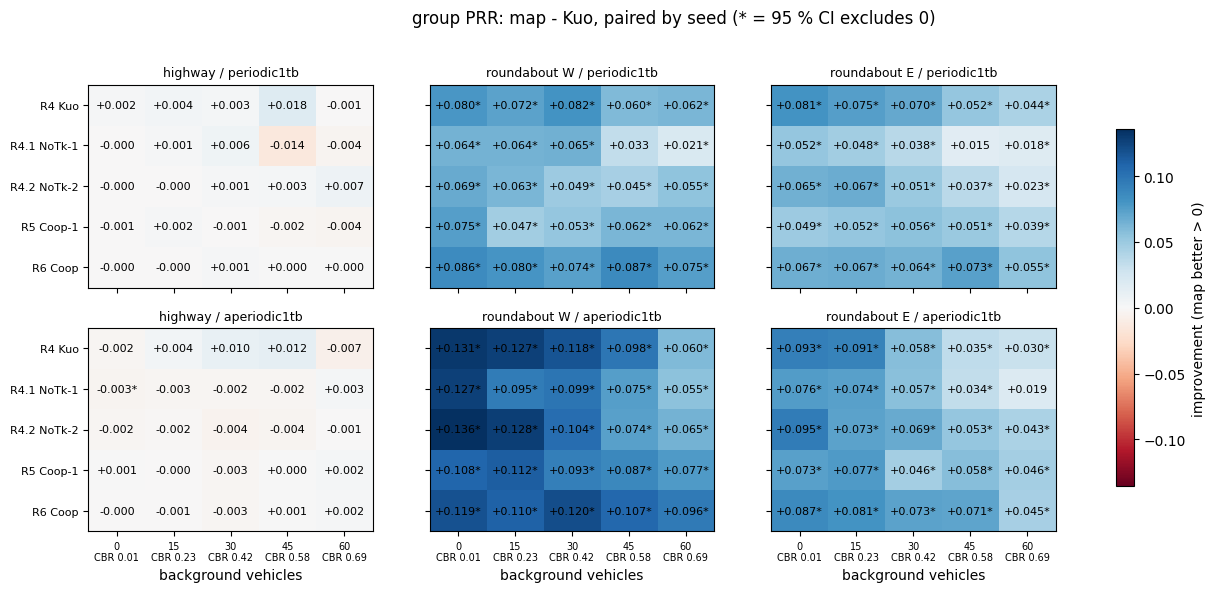

verdict,better,tie,worse,mean d,min d,max d
arm,,,,,,
R4,20,10,0,0.0519,-0.0067,0.1311
R4.1,17,12,1,0.0370,-0.0139,0.1265
R4.2,20,10,0,0.0453,-0.0043,0.1359
R5,20,10,0,0.0439,-0.0036,0.1118
R6,20,10,0,0.0546,-0.0025,0.1202


In [6]:
def delta_heatmap(metric, fmt='{:+.3f}'):
    D = map_vs_kuo(metric)
    sign = 1 if HIGHER[metric] else -1
    vmax = max(1e-9, (sign * D.d).abs().max()) if len(D) else 1
    fig, axes = plt.subplots(len(TRAFS), len(SCENS), figsize=(5.2 * len(SCENS), 2.9 * len(TRAFS)),
                             sharex=True, sharey=True, squeeze=False)
    for i, tr in enumerate(TRAFS):
        for j, sc in enumerate(SCENS):
            ax = axes[i, j]
            x = D[(D.sc == sc) & (D.tr == tr)]
            M = np.full((len(HELPER_ARMS), len(NBGS)), np.nan)
            for _, r in x.iterrows():
                M[HELPER_ARMS.index(r.arm), NBGS.index(r.nbg)] = sign * r.d
                ax.text(NBGS.index(r.nbg), HELPER_ARMS.index(r.arm),
                        fmt.format(r.d) + ('*' if r.verdict in ('better', 'worse') else ''),
                        ha='center', va='center', fontsize=8)
            im = ax.imshow(M, cmap='RdBu', vmin=-vmax, vmax=vmax, aspect='auto')
            ax.set_xticks(range(len(NBGS)), [f'{n}\nCBR {CBR.get((sc, tr, n), np.nan):.2f}' for n in NBGS], fontsize=7)
            ax.set_yticks(range(len(HELPER_ARMS)), [f'{a} {NAME[a]}' for a in HELPER_ARMS], fontsize=8)
            ax.set_title(f'{SCEN_NAME[sc]} / {tr}', fontsize=9)
            if i == len(TRAFS) - 1:
                ax.set_xlabel('background vehicles')
    fig.colorbar(im, ax=axes, shrink=0.8, label='improvement (map better > 0)')
    fig.suptitle(f'{LABEL[metric]}: map - Kuo, paired by seed (* = 95 % CI excludes 0)', y=1.01)
    plt.show()
    return D

def verdict_counts(D):
    t = D.pivot_table(index='arm', columns='verdict', values='d', aggfunc='size').fillna(0).astype(int)
    t = t.reindex(columns=[c for c in ('better', 'tie', 'worse', 'n/a') if c in t.columns])
    t['mean d'] = D.groupby('arm').d.mean().round(4)
    t['min d'] = D.groupby('arm').d.min().round(4)
    t['max d'] = D.groupby('arm').d.max().round(4)
    return t.reindex([a for a in HELPER_ARMS if a in t.index])

D_prr = delta_heatmap('prr')
verdict_counts(D_prr)

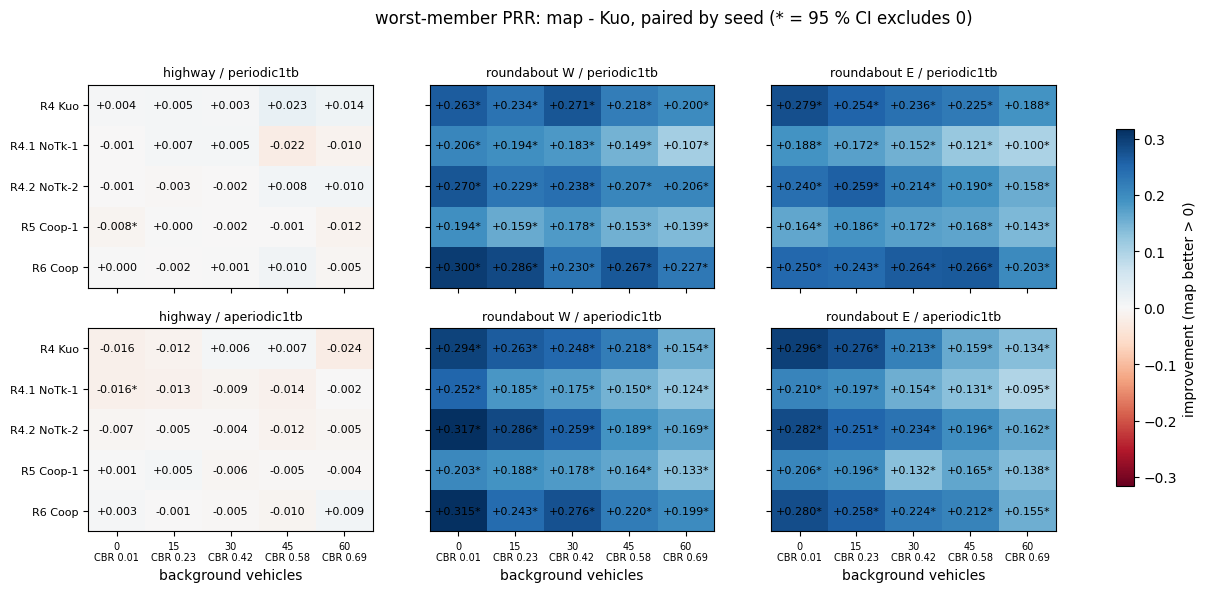

verdict,better,tie,worse,mean d,min d,max d
arm,,,,,,
R4,20,10,0,0.1544,-0.0235,0.2959
R4.1,20,9,1,0.1056,-0.0223,0.2520
R4.2,20,10,0,0.1512,-0.0118,0.3166
R5,20,9,1,0.1109,-0.0123,0.2061
R6,20,10,0,0.1639,-0.0095,0.3145


In [7]:
D_worst = delta_heatmap('prr_worst')
verdict_counts(D_worst)

In [8]:
# the cells where map changes the group PRR significantly, largest first
D_prr[D_prr.verdict.isin(['better', 'worse'])].sort_values('d', ascending=False).round(4)

,sc,tr,nbg,a,b,d,n,ci,verdict,arm
70,rbt,aperiodic1tb,0,0.8884,0.7525,0.1359,10,0.0151,better,R4.2
10,rbt,aperiodic1tb,0,0.8703,0.7393,0.1311,10,0.0107,better,R4
71,rbt,aperiodic1tb,15,0.8454,0.7171,0.1283,10,0.0168,better,R4.2
40,rbt,aperiodic1tb,0,0.8638,0.7372,0.1265,10,0.0181,better,R4.1
11,rbt,aperiodic1tb,15,0.8252,0.6987,0.1265,10,0.0210,better,R4
...,...,...,...,...,...,...,...,...,...,...
24,rbtE,aperiodic1tb,60,0.6682,0.6384,0.0297,10,0.0207,better,R4
89,rbtE,periodic1tb,60,0.8642,0.8410,0.0232,10,0.0123,better,R4.2
49,rbt,periodic1tb,60,0.7563,0.7353,0.0210,10,0.0205,better,R4.1
59,rbtE,periodic1tb,60,0.8075,0.7897,0.0179,10,0.0159,better,R4.1


## 4. Gains over the leader-only schemes, Kuo vs map
Paired gain (helper arm - leader scheme) per load. Each panel: one helper arm in one scenario x traffic; dashed =
Kuo, solid = map, shaded = 95 % CI. Two references:
* the leader scheme with the same HARQ mode: R4 vs Blind (R1), R4.1 and R5 vs Opt 1 (R2), R4.2 and R6 vs Opt 2 (R3);
* Opt 2 (R3) for every arm, the strongest leader scheme in the v3 data (as in v2).

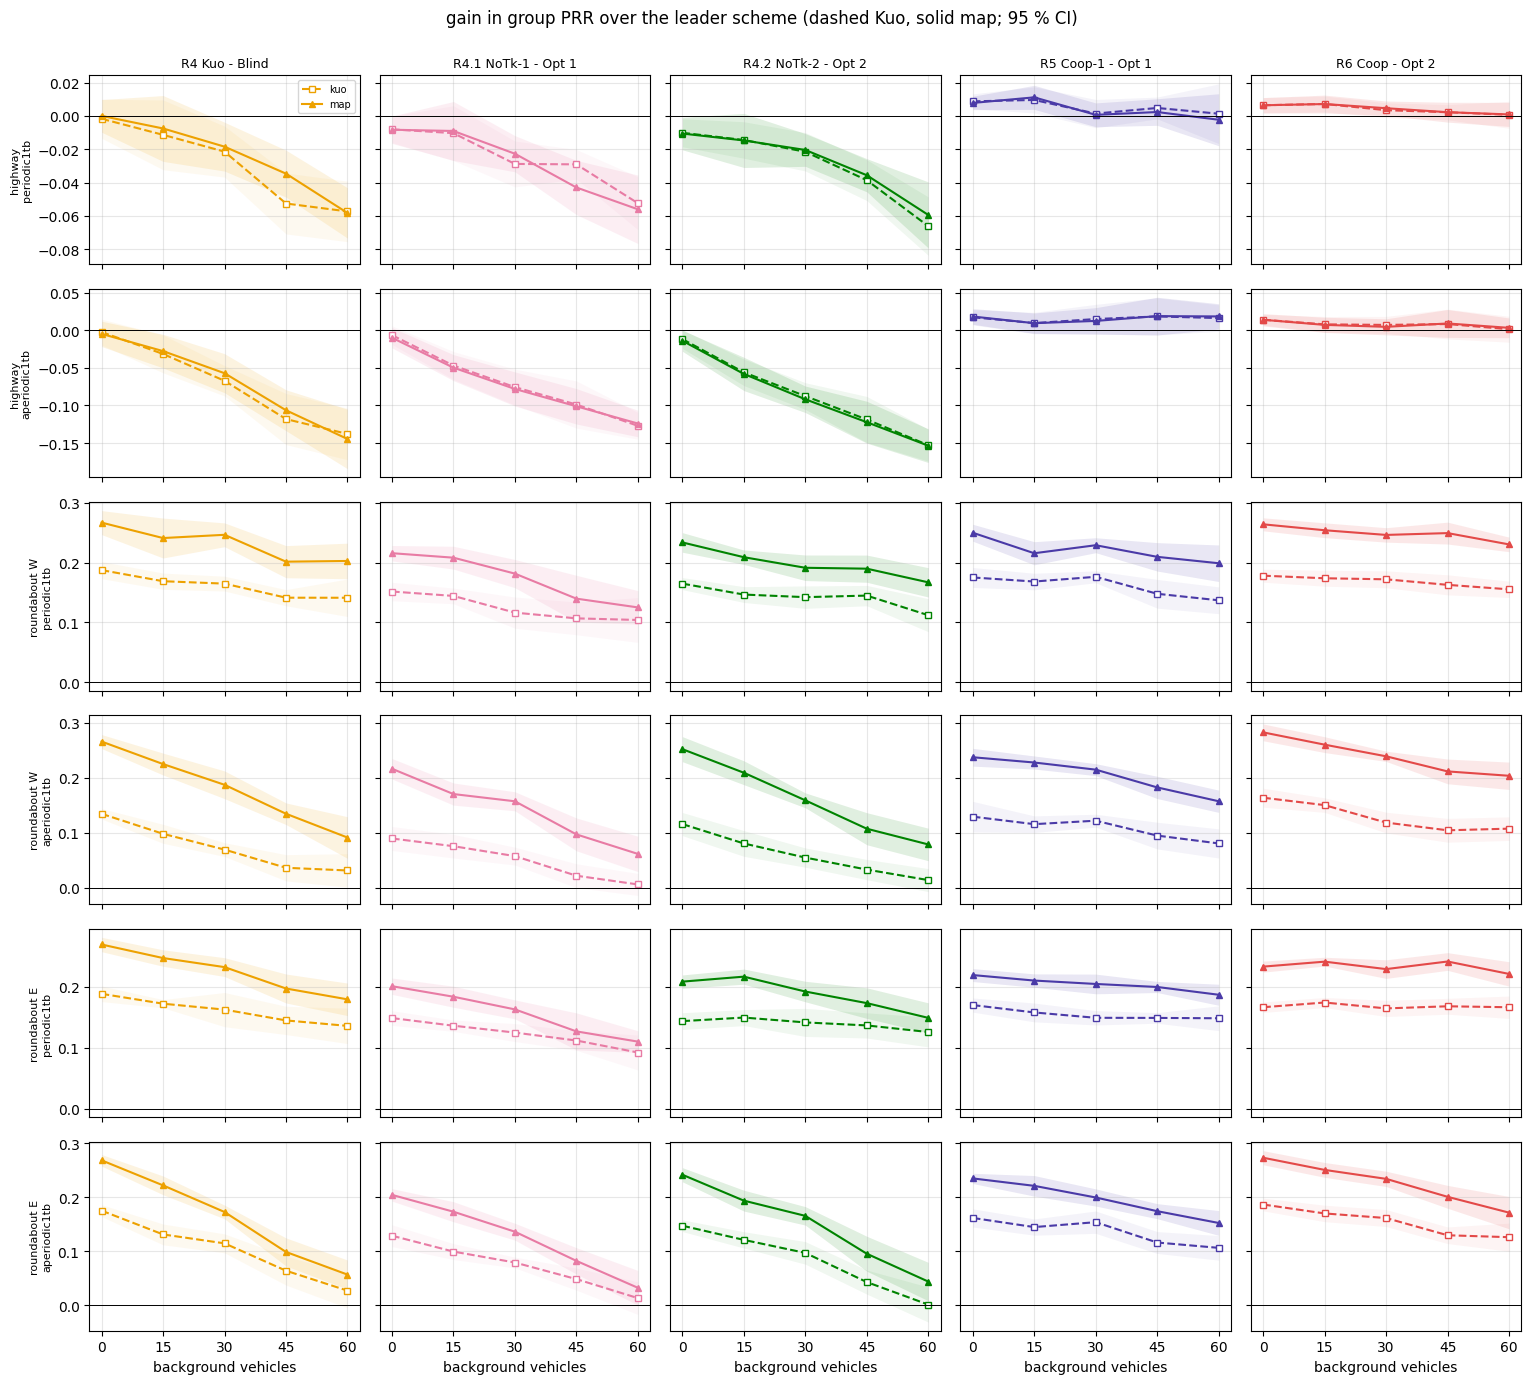

In [9]:
SAME_MODE = {'R4': 'R1', 'R4.1': 'R2', 'R4.2': 'R3', 'R5': 'R2', 'R6': 'R3'}

def gain_grid(metric, base_of):
    fig, axes = plt.subplots(len(SCENS) * len(TRAFS), len(HELPER_ARMS),
                             figsize=(3.1 * len(HELPER_ARMS), 2.3 * len(SCENS) * len(TRAFS)),
                             sharex=True, sharey='row', squeeze=False)
    rows = []
    for a_i, arm in enumerate(HELPER_ARMS):
        base = base_of[arm]
        for sel, ls, mk in (('kuo', '--', 's'), ('map', '-', '^')):
            G = paired((arm, sel), (base, 'leader'), metric)
            rows.append(G.assign(arm=arm, sel=sel, base=base))
            for r_i, (sc, tr) in enumerate([(s, t) for s in SCENS for t in TRAFS]):
                ax = axes[r_i, a_i]
                # reindexed on every load: a missing load breaks the line instead of bridging it
                g = G[(G.sc == sc) & (G.tr == tr)].set_index('nbg').reindex(NBGS).reset_index()
                if g.d.notna().any():
                    ax.plot(g.nbg, g.d, ls, marker=mk, ms=4, color=COL[arm], mfc='white' if sel == 'kuo' else COL[arm],
                            lw=1.5, label=sel)
                    ax.fill_between(g.nbg, g.d - g.ci, g.d + g.ci, color=COL[arm], alpha=.12 if sel == 'map' else .06, lw=0)
                ax.axhline(0, color='k', lw=.6)
                ax.grid(alpha=.3)
                if r_i == 0:
                    ax.set_title(f'{arm} {NAME[arm]} - {NAME[base]}', fontsize=9)
                if a_i == 0:
                    ax.set_ylabel(f'{SCEN_NAME[sc]}\n{tr}', fontsize=8)
                if r_i == len(SCENS) * len(TRAFS) - 1:
                    ax.set_xlabel('background vehicles'); ax.set_xticks(NBGS)
    axes[0, 0].legend(fontsize=7)
    fig.suptitle(f'gain in {LABEL[metric]} over the leader scheme (dashed Kuo, solid map; 95 % CI)', y=1.0)
    fig.tight_layout(); plt.show()
    return pd.concat(rows, ignore_index=True)

G_same = gain_grid('prr', SAME_MODE)

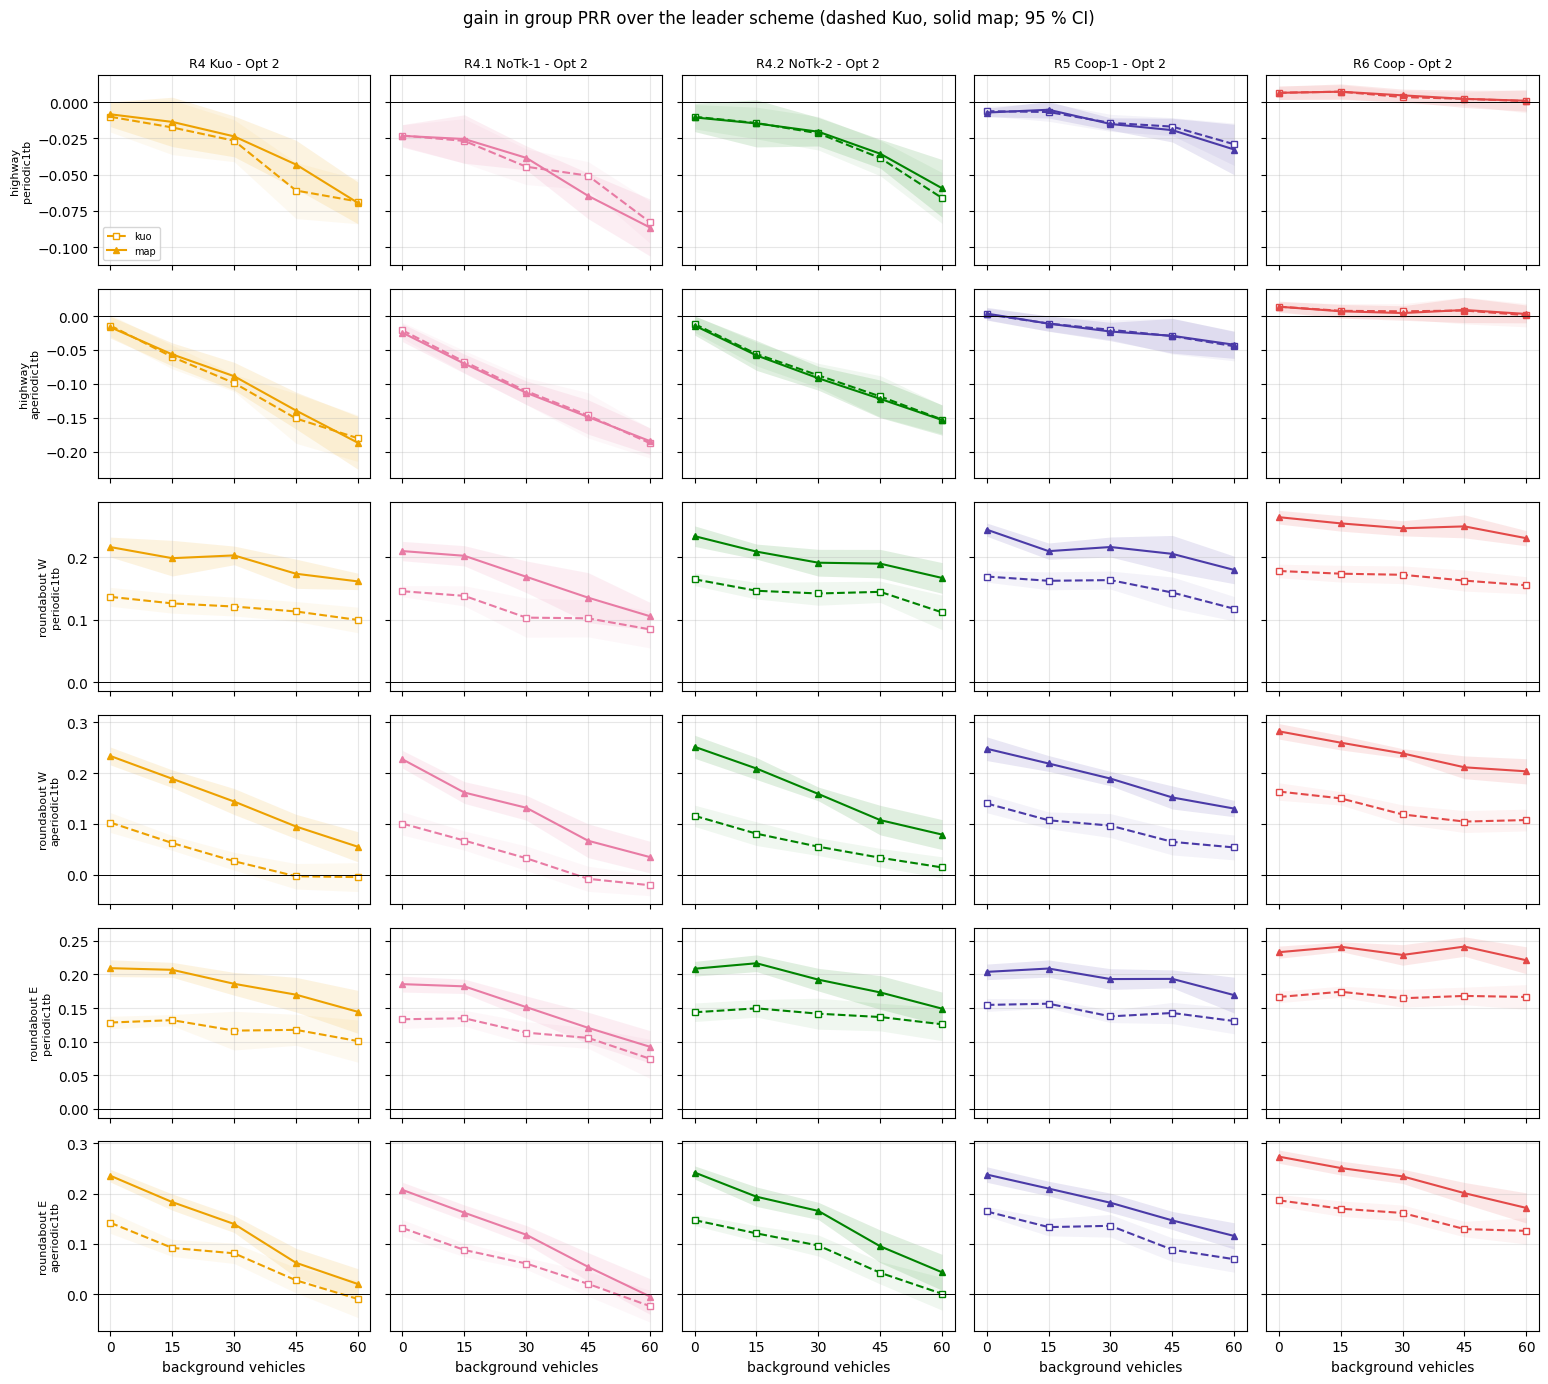

In [10]:
G_r3 = gain_grid('prr', {a: 'R3' for a in HELPER_ARMS})

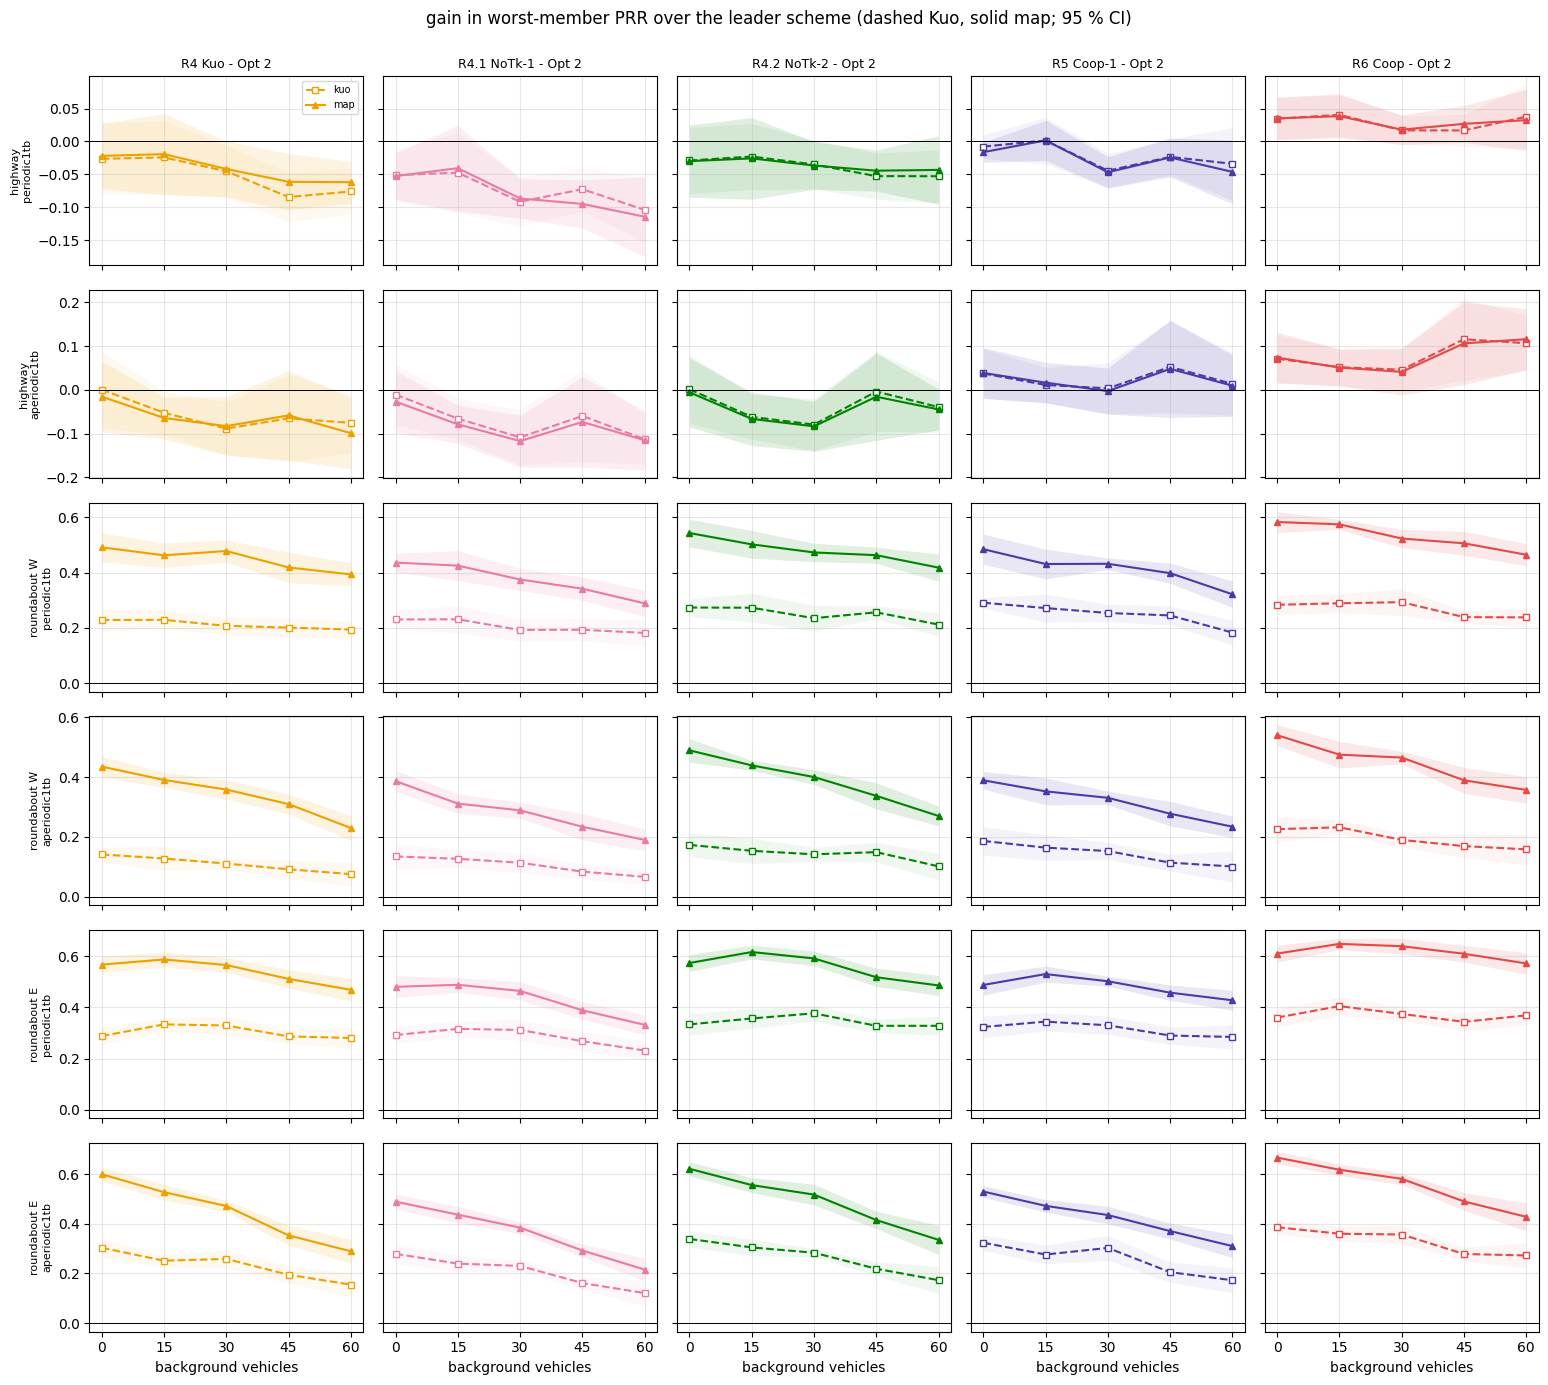

In [11]:
G_r3_worst = gain_grid('prr_worst', {a: 'R3' for a in HELPER_ARMS})

In [12]:
def gain_table(G):
    # gain over the leader scheme, Kuo and map side by side, per cell; 'map - kuo' = change of the gain
    t = G.pivot_table(index=['sc', 'tr', 'nbg'], columns=['arm', 'sel'], values='d')
    for a in HELPER_ARMS:
        if (a, 'kuo') in t.columns and (a, 'map') in t.columns:
            t[(a, 'map - kuo')] = t[(a, 'map')] - t[(a, 'kuo')]
    return t.reindex(columns=[(a, s) for a in HELPER_ARMS for s in ('kuo', 'map', 'map - kuo') if (a, s) in t.columns]).round(3)
gain_table(G_r3)

arm                       R4                    R4.1                    R4.2                      R5                      R6                 
sel                      kuo    map map - kuo    kuo    map map - kuo    kuo    map map - kuo    kuo    map map - kuo    kuo    map map - kuo
sc   tr           nbg                                                                                                                        
hwy  aperiodic1tb 0   -0.014 -0.017    -0.002 -0.021 -0.025    -0.003 -0.012 -0.014    -0.002  0.003  0.004     0.001  0.014  0.014    -0.000
                  15  -0.060 -0.057     0.004 -0.067 -0.070    -0.003 -0.056 -0.058    -0.002 -0.011 -0.011    -0.000  0.008  0.007    -0.001
                  30  -0.099 -0.089     0.010 -0.111 -0.113    -0.002 -0.088 -0.092    -0.004 -0.020 -0.023    -0.003  0.007  0.004    -0.003
                  45  -0.151 -0.139     0.012 -0.147 -0.149    -0.002 -0.119 -0.122    -0.004 -0.030 -0.029     0.000  0.008  0.009     0.001
                  60  -0.180 -0.187    -0.007 -0.188 -0.185     0.003 -0.153 -0.153    -0.001 -0.045 -0.042     0.002  0.001  0.003     0.002
     periodic1tb  0   -0.010 -0.008     0.002 -0.023 -0.023    -0.000 -0.010 -0.011    -0.000 -0.006 -0.007    -0.001  0.006  0.006    -0.000
                  15  -0.018 -0.014     0.004 -0.027 -0.026     0.001 -0.014 -0.015    -0.000 -0.007 -0.005     0.002  0.007  0.007    -0.000
                  30  -0.027 -0.024     0.003 -0.045 -0.038     0.006 -0.022 -0.020     0.001 -0.014 -0.015    -0.001  0.003  0.005     0.001
                  45  -0.061 -0.043     0.018 -0.051 -0.065    -0.014 -0.039 -0.036     0.003 -0.017 -0.019    -0.002  0.002  0.002     0.000
                  60  -0.069 -0.069    -0.001 -0.083 -0.086    -0.004 -0.066 -0.059     0.007 -0.029 -0.033    -0.004  0.001  0.001     0.000
rbt  aperiodic1tb 0    0.103  0.234     0.131  0.101  0.227     0.127  0.116  0.252     0.136  0.140  0.248     0.108  0.164  0.282     0.119
                  15   0.062  0.189     0.127  0.067  0.162     0.095  0.081  0.209     0.128  0.107  0.219     0.112  0.150  0.260     0.110
                  30   0.026  0.144     0.118  0.032  0.132     0.099  0.055  0.159     0.104  0.097  0.189     0.093  0.119  0.239     0.120
                  45  -0.003  0.095     0.098 -0.008  0.067     0.075  0.033  0.107     0.074  0.065  0.152     0.087  0.105  0.211     0.107
                  60  -0.005  0.055     0.060 -0.021  0.035     0.055  0.014  0.079     0.065  0.054  0.130     0.077  0.108  0.203     0.096
     periodic1tb  0    0.137  0.216     0.080  0.146  0.210     0.064  0.165  0.234     0.069  0.169  0.244     0.075  0.178  0.264     0.086
                  15   0.126  0.199     0.072  0.138  0.202     0.064  0.147  0.209     0.063  0.162  0.210     0.047  0.174  0.254     0.080
                  30   0.121  0.203     0.082  0.104  0.169     0.065  0.142  0.191     0.049  0.164  0.216     0.053  0.172  0.246     0.074
                  45   0.113  0.174     0.060  0.102  0.135     0.033  0.145  0.190     0.045  0.144  0.205     0.062  0.163  0.249     0.087
                  60   0.100  0.161     0.062  0.085  0.106     0.021  0.112  0.167     0.055  0.118  0.180     0.062  0.155  0.230     0.075
rbtE aperiodic1tb 0    0.142  0.235     0.093  0.132  0.207     0.076  0.147  0.242     0.095  0.164  0.238     0.073  0.187  0.273     0.087
                  15   0.092  0.183     0.091  0.088  0.162     0.074  0.121  0.194     0.073  0.133  0.210     0.077  0.170  0.251     0.081
                  30   0.081  0.140     0.058  0.061  0.118     0.057  0.097  0.166     0.069  0.136  0.182     0.046  0.161  0.234     0.073
                  45   0.028  0.063     0.035  0.021  0.054     0.034  0.043  0.095     0.053  0.089  0.147     0.058  0.130  0.201     0.071
                  60  -0.009  0.020     0.030 -0.023 -0.004     0.019  0.001  0.044     0.043  0.070  0.116     0.046  0.126  0.171     0.045
     periodic1tb  0    0

## 5. Reliability levels per load
Mean over the seeds. Dotted / circle = leader schemes, dashed / open square = Kuo, solid / triangle = map.

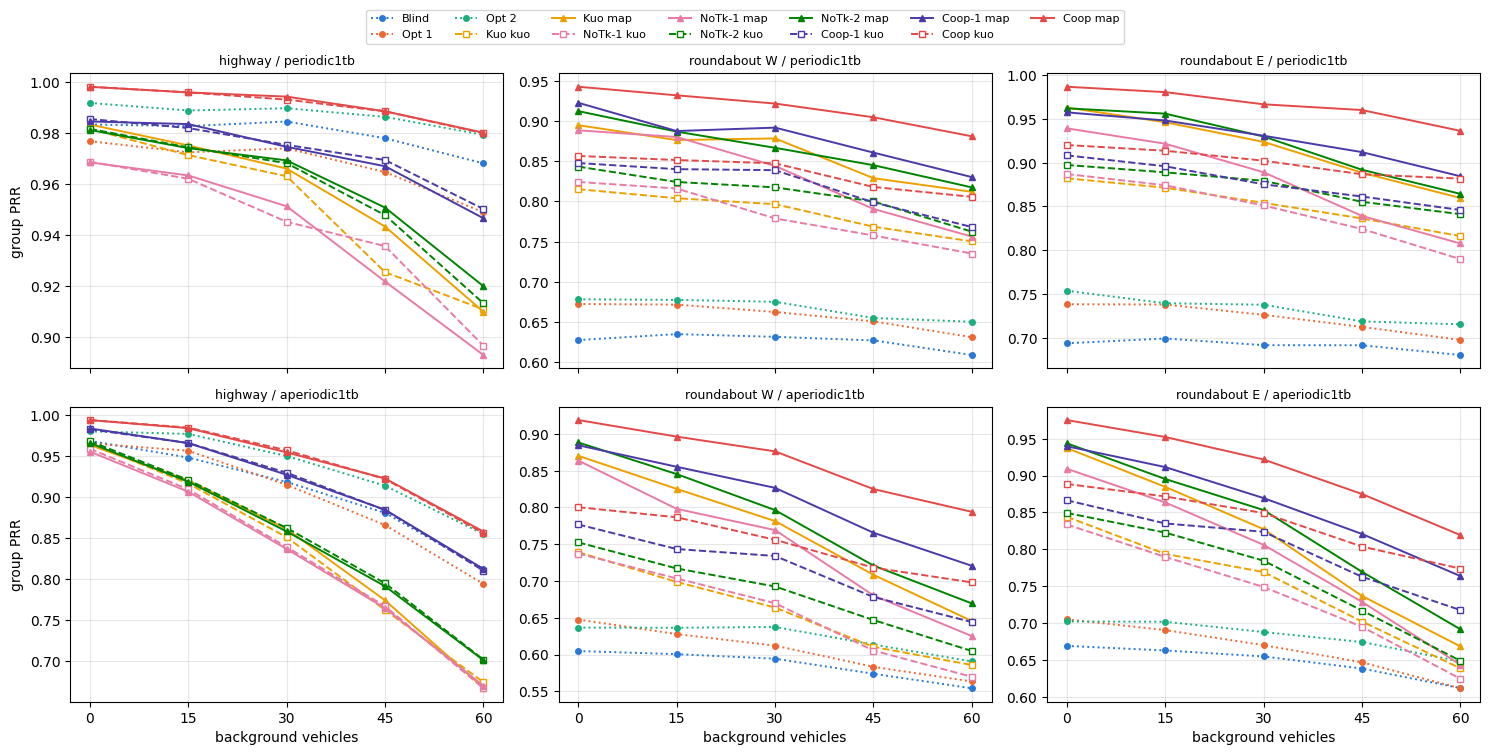

In [13]:
def level_plot(metric):
    fig, axes = plt.subplots(len(TRAFS), len(SCENS), figsize=(5.0 * len(SCENS), 3.6 * len(TRAFS)),
                             sharex=True, squeeze=False)
    m = R.groupby(['arm', 'sel'] + KEYS)[metric].mean().reset_index()
    for i, tr in enumerate(TRAFS):
        for j, sc in enumerate(SCENS):
            ax = axes[i, j]
            x = m[(m.sc == sc) & (m.tr == tr)]
            for arm, sel in [(a, 'leader') for a in LEADER_ARMS] + [(a, s) for a in HELPER_ARMS for s in ('kuo', 'map')]:
                g = x[(x.arm == arm) & (x.sel == sel)].set_index('nbg').reindex(NBGS).reset_index()
                if g[metric].isna().all():
                    continue
                ls, mk = {'leader': (':', 'o'), 'kuo': ('--', 's'), 'map': ('-', '^')}[sel]
                ax.plot(g.nbg, g[metric], ls, marker=mk, ms=4, color=COL[arm], lw=1.4,
                        mfc='white' if sel == 'kuo' else COL[arm],
                        label=NAME[arm] if sel == 'leader' else f'{NAME[arm]} {sel}')
            ax.set_title(f'{SCEN_NAME[sc]} / {tr}', fontsize=9); ax.grid(alpha=.3); ax.set_xticks(NBGS)
            if j == 0: ax.set_ylabel(LABEL[metric])
            if i == len(TRAFS) - 1: ax.set_xlabel('background vehicles')
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.legend(h, l, loc='upper center', ncol=7, fontsize=8, bbox_to_anchor=(0.5, 1.05))
    fig.tight_layout(); plt.show()

level_plot('prr')

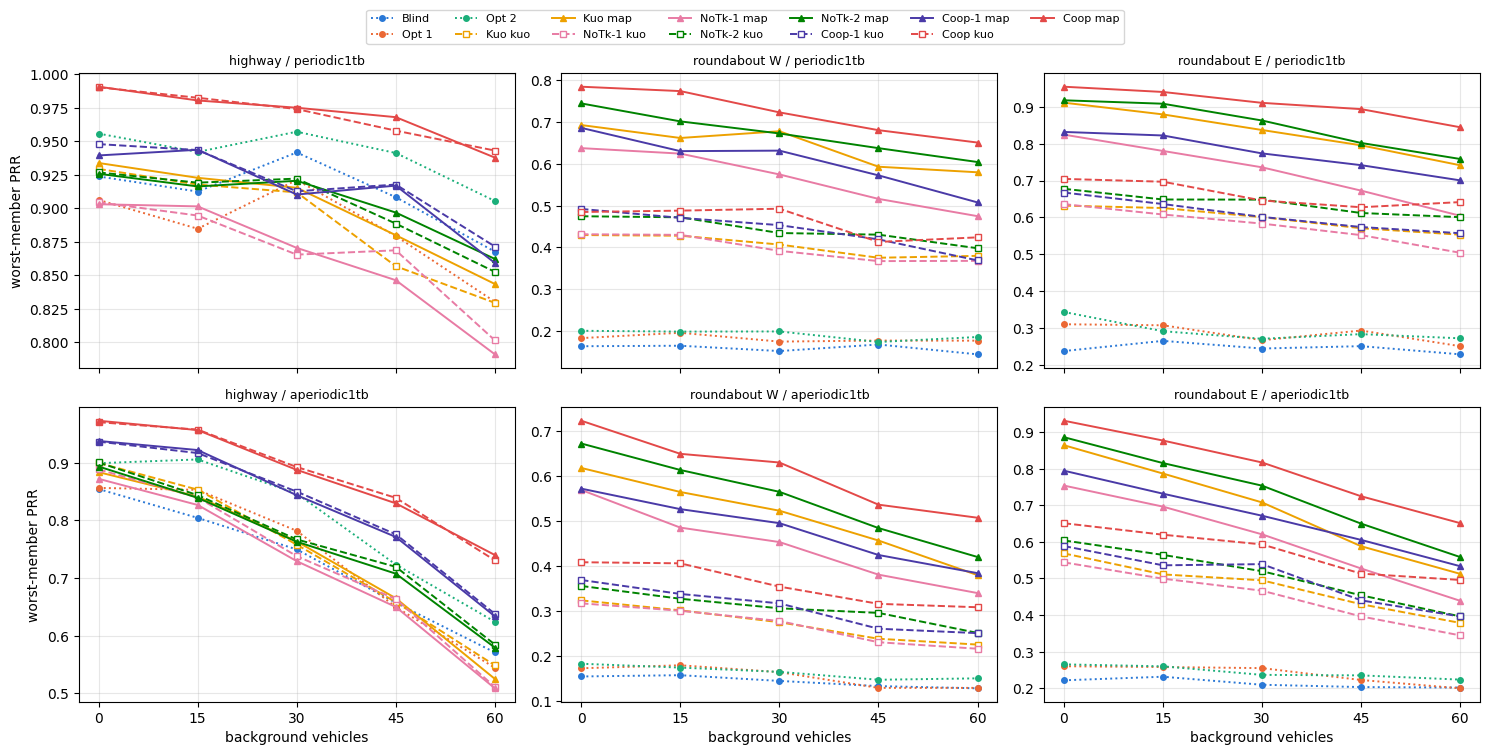

In [14]:
level_plot('prr_worst')

## 6. Disconnection time
`disc_frac` = share of the window a member spends in an outage (mean over members); `dt_mean` = mean duration of
an outage (paper definition, window edges kept). Lower is better: blue = map better.

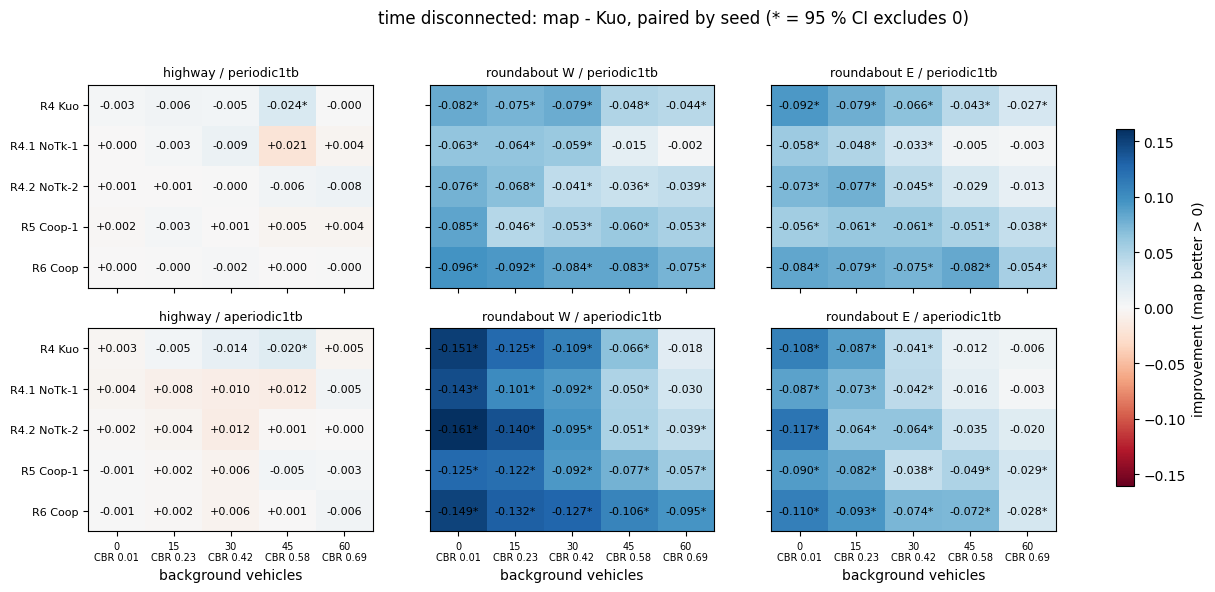

verdict,better,tie,mean d,min d,max d
arm,,,,,
R4,19,11,-0.0476,-0.1510,0.0048
R4.1,13,17,-0.0315,-0.1433,0.0211
R4.2,16,14,-0.0425,-0.1610,0.0123
R5,20,10,-0.0440,-0.1254,0.0057
R6,20,10,-0.0597,-0.1494,0.0057


In [15]:
D_disc = delta_heatmap('disc_frac')
verdict_counts(D_disc)

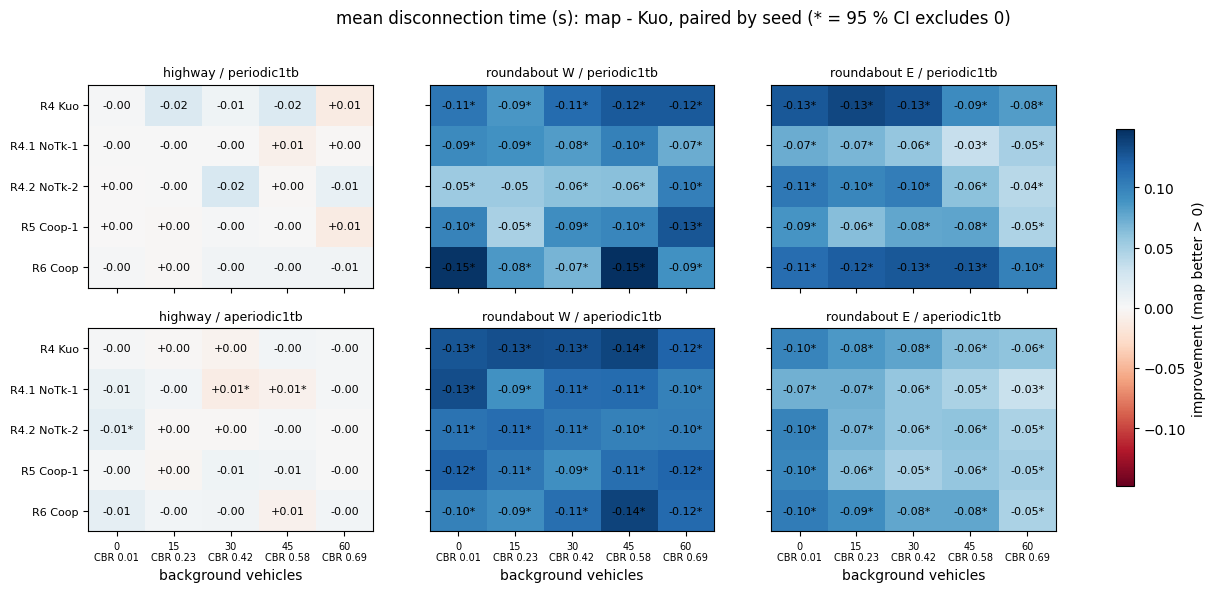

verdict,better,tie,worse,mean d,min d,max d
arm,,,,,,
R4,20,10,0,-0.0729,-0.1362,0.0119
R4.1,20,8,2,-0.0514,-0.1310,0.0112
R4.2,20,10,0,-0.0550,-0.1133,0.0020
R5,20,10,0,-0.0559,-0.1267,0.0127
R6,20,10,0,-0.0704,-0.1483,0.0061


In [16]:
D_dt = delta_heatmap('dt_mean', fmt='{:+.2f}')
verdict_counts(D_dt)

## 7. Spectrum
`res_deliv` = PSSCH subchannel-slots actually transmitted (leader + helper) per delivered (packet, member) pair.
Every scheme announces the same 3-slot grant in SCI-1A, so this is what is transmitted, not what is reserved.
Lower is better: blue = map cheaper.

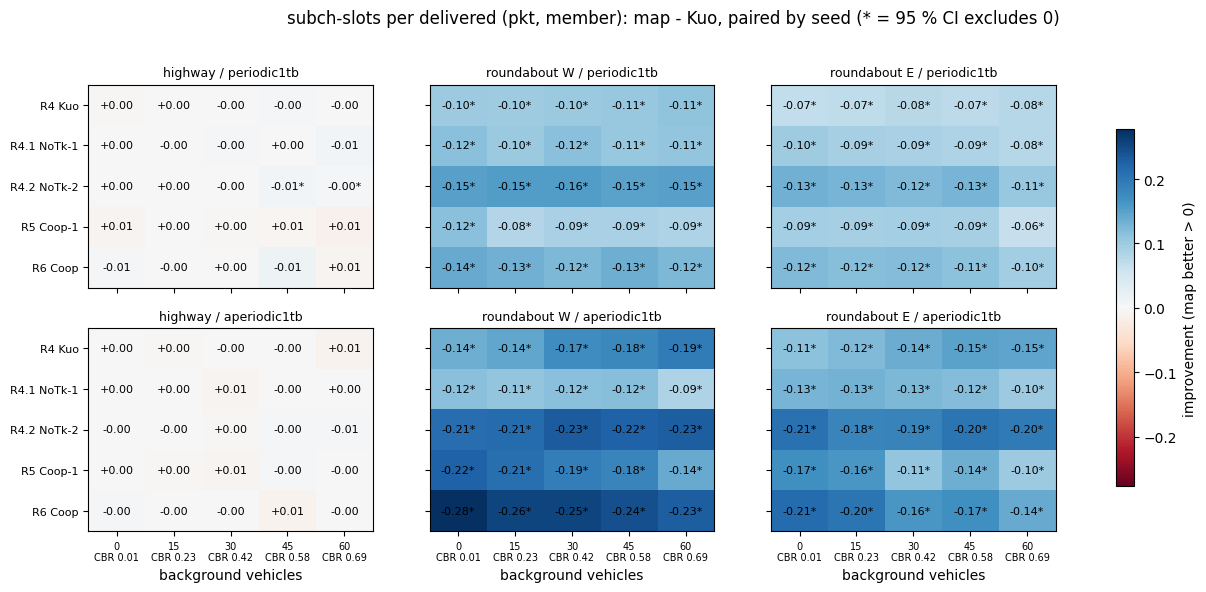

verdict,better,tie,mean d,min d,max d
arm,,,,,
R4,20,10,-0.0791,-0.1936,0.0103
R4.1,20,10,-0.0717,-0.1318,0.0069
R4.2,22,8,-0.1160,-0.2303,0.0032
R5,20,10,-0.0828,-0.2247,0.0112
R6,20,10,-0.1127,-0.2776,0.0105


In [17]:
D_res = delta_heatmap('res_deliv', fmt='{:+.2f}')
verdict_counts(D_res)

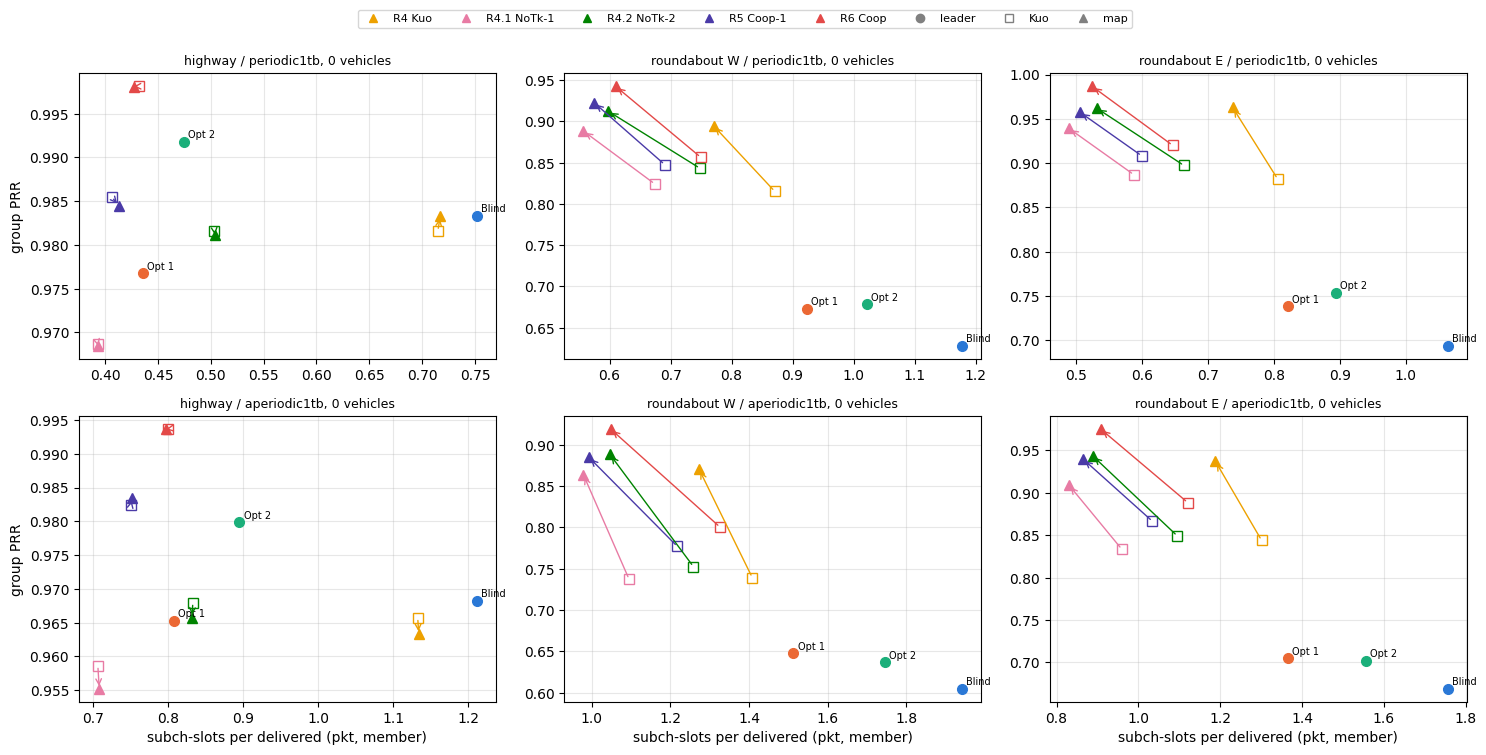

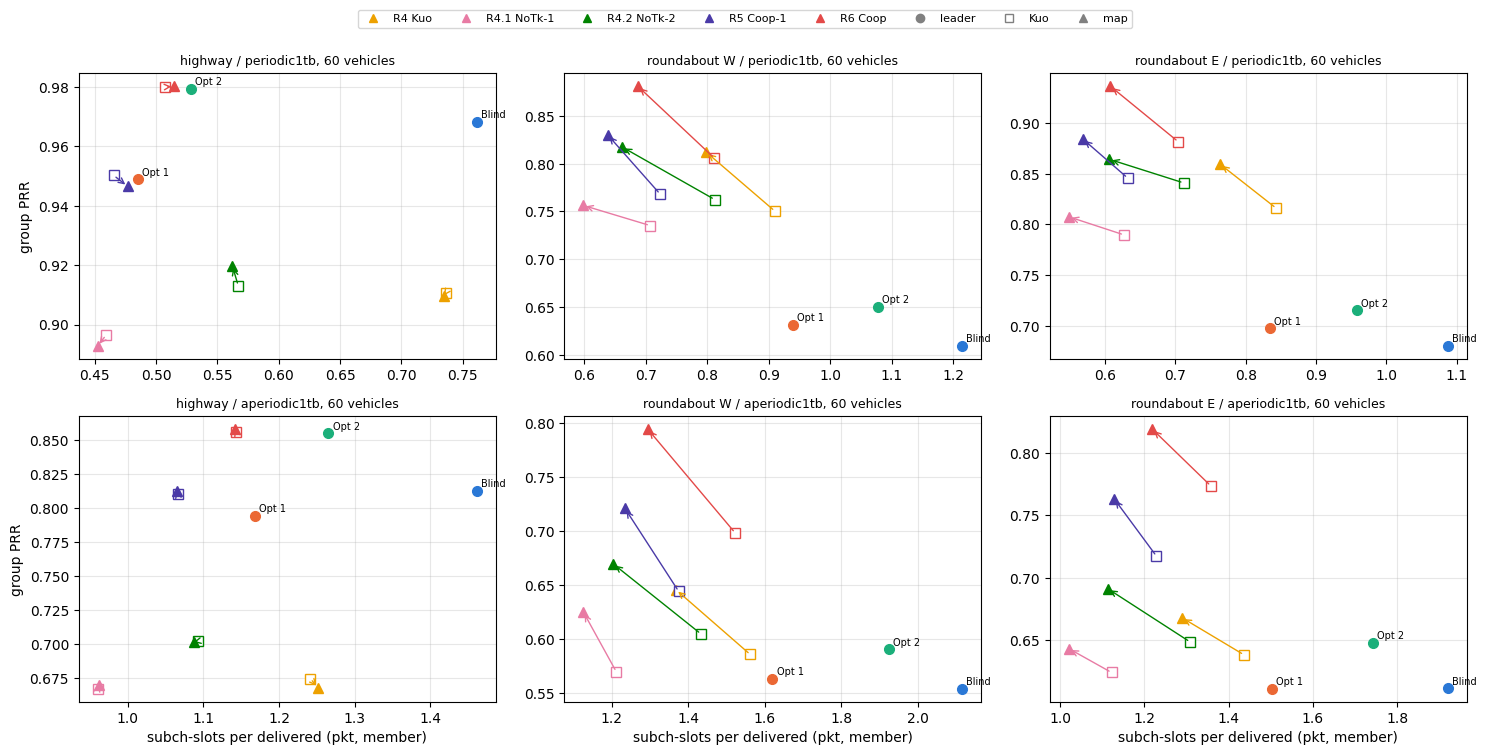

In [18]:
def pareto(nbg):
    # group PRR vs cost per cell; leader schemes, Kuo (open) and map (filled); arrows Kuo -> map
    m = R[R.nbg == nbg].groupby(['arm', 'sel', 'sc', 'tr'])[['prr', 'res_deliv']].mean().reset_index()
    fig, axes = plt.subplots(len(TRAFS), len(SCENS), figsize=(5.0 * len(SCENS), 3.6 * len(TRAFS)), squeeze=False)
    for i, tr in enumerate(TRAFS):
        for j, sc in enumerate(SCENS):
            ax = axes[i, j]
            x = m[(m.sc == sc) & (m.tr == tr)]
            for _, r in x.iterrows():
                mk = {'leader': 'o', 'kuo': 's', 'map': '^'}[r.sel]
                ax.plot(r.res_deliv, r.prr, mk, color=COL[r.arm], mfc='white' if r.sel == 'kuo' else COL[r.arm], ms=7)
                if r.sel == 'leader':
                    ax.annotate(NAME[r.arm], (r.res_deliv, r.prr), fontsize=7, xytext=(3, 3), textcoords='offset points')
            for a in HELPER_ARMS:
                k, p = x[(x.arm == a) & (x.sel == 'kuo')], x[(x.arm == a) & (x.sel == 'map')]
                if len(k) and len(p):
                    ax.annotate('', xy=(p.res_deliv.iloc[0], p.prr.iloc[0]), xytext=(k.res_deliv.iloc[0], k.prr.iloc[0]),
                                arrowprops=dict(arrowstyle='->', color=COL[a], lw=1))
            ax.set_title(f'{SCEN_NAME[sc]} / {tr}, {nbg} vehicles', fontsize=9); ax.grid(alpha=.3)
            if j == 0: ax.set_ylabel('group PRR')
            if i == len(TRAFS) - 1: ax.set_xlabel(LABEL['res_deliv'])
    hs = [plt.Line2D([], [], color=COL[a], marker='^', ls='', label=f'{a} {NAME[a]}') for a in HELPER_ARMS]
    hs += [plt.Line2D([], [], color='grey', marker=mk, mfc=mf, ls='', label=lb)
           for mk, mf, lb in (('o', 'grey', 'leader'), ('s', 'white', 'Kuo'), ('^', 'grey', 'map'))]
    fig.legend(handles=hs, loc='upper center', ncol=8, fontsize=8, bbox_to_anchor=(0.5, 1.05))
    fig.tight_layout(); plt.show()

for n in (0, 60):
    pareto(n)

## 8. Which helper does each selector pick?
Share of the TBs in which each member is named helper (`helper_share_m1..m8` of the run CSV), R6 runs, mean over
seeds. The choice depends on positions and the TB width only, so it is close to identical across the five arms.
Below: changes of helper per second, and for R6 the share of named TBs whose helper failed the leader's first
transmission (`helper_corrupt_tx / helper_named_tx`; the Kuo R6 helper missed copy 1 in 67 % of the packets on the
loaded highway).

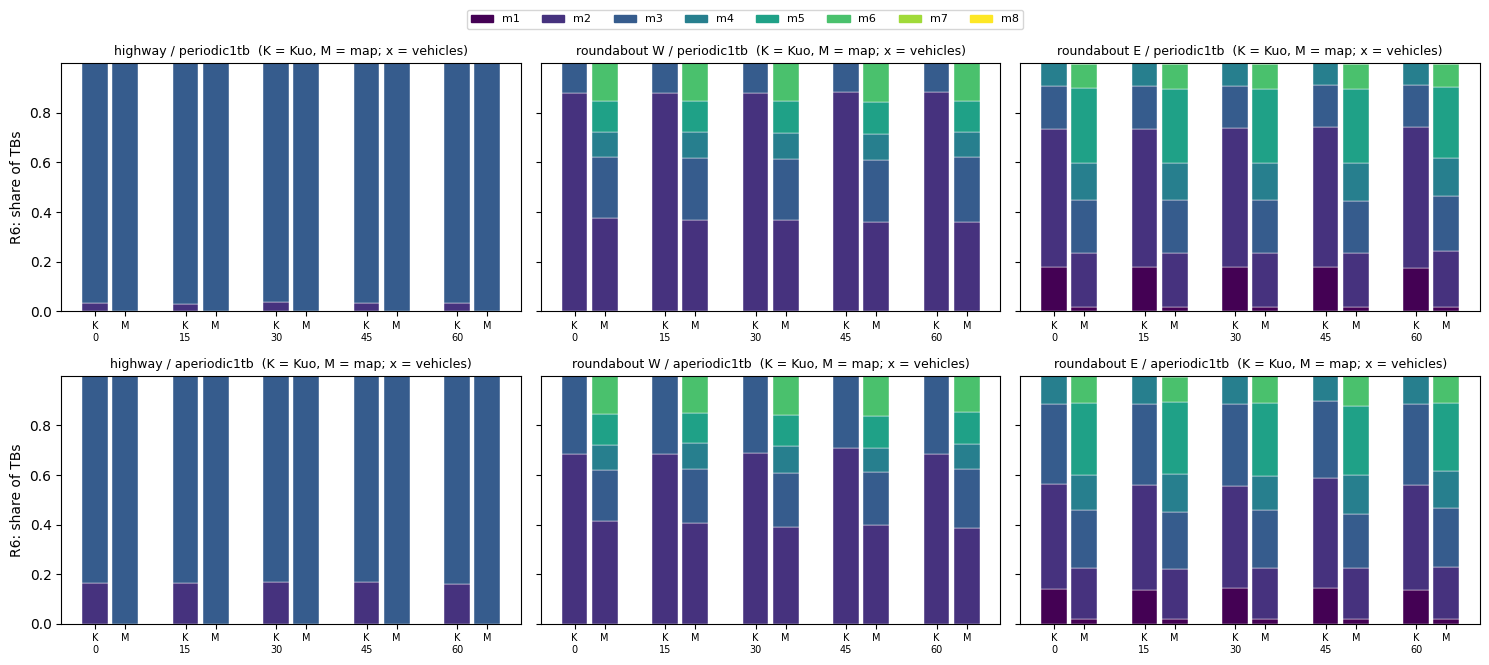

In [19]:
SHARE = [f'helper_share_m{i}' for i in range(1, 9)]

def share_plot(arm='R6'):
    x = R[(R.arm == arm) & R.sel.isin(['kuo', 'map'])].groupby(['sc', 'tr', 'nbg', 'sel'])[SHARE].mean()
    cols = plt.cm.viridis(np.linspace(0, 1, 8))
    fig, axes = plt.subplots(len(TRAFS), len(SCENS), figsize=(5.0 * len(SCENS), 3.2 * len(TRAFS)),
                             sharey=True, squeeze=False)
    for i, tr in enumerate(TRAFS):
        for j, sc in enumerate(SCENS):
            ax = axes[i, j]
            pos, labs = [], []
            for k, n in enumerate(NBGS):
                for s_i, sel in enumerate(('kuo', 'map')):
                    if (sc, tr, n, sel) not in x.index:
                        continue
                    v = x.loc[(sc, tr, n, sel)].values
                    xp = 3 * k + s_i
                    ax.bar(xp, v, bottom=np.r_[0, np.cumsum(v)[:-1]], color=cols, width=.85,
                           edgecolor='white', lw=.3)
                    pos.append(xp); labs.append(f'{"K" if sel == "kuo" else "M"}\n{n}' if s_i == 0 else 'M')
            ax.set_xticks(pos, labs, fontsize=7)
            ax.set_title(f'{SCEN_NAME[sc]} / {tr}  (K = Kuo, M = map; x = vehicles)', fontsize=9)
            if j == 0: ax.set_ylabel(f'{arm}: share of TBs')
    hs = [plt.Rectangle((0, 0), 1, 1, color=cols[m]) for m in range(8)]
    fig.legend(hs, [f'm{m + 1}' for m in range(8)], loc='upper center', ncol=8, fontsize=8, bbox_to_anchor=(0.5, 1.04))
    fig.tight_layout(); plt.show()

share_plot('R6')

In [20]:
h = R[(R.arm == 'R6') & R.sel.isin(['kuo', 'map'])].copy()
h['helper_missed_copy1'] = h.helper_corrupt_tx / h.helper_named_tx.replace(0, np.nan)
t = h.groupby(['sc', 'tr', 'nbg', 'sel'])[['helper_missed_copy1', 'helper_changes_per_s', 'hsel_cam_age_ms_mean']].mean()
t = t.unstack('sel')
t.columns = [f'{m} {s}' for m, s in t.columns]
t.round(3)

helper_missed_copy1 kuo  helper_missed_copy1 map  helper_changes_per_s kuo  helper_changes_per_s map  hsel_cam_age_ms_mean kuo  hsel_cam_age_ms_mean map
sc   tr           nbg                                                                                                                                                          
hwy  aperiodic1tb 0                      0.092                    0.095                     2.757                     0.000                    50.090                    50.217
                  15                     0.132                    0.133                     2.662                     0.000                    49.526                    49.851
                  30                     0.192                    0.192                     2.797                     0.000                    49.813                    49.518
                  45                     0.220                    0.217                     2.851                     0.000                    49.668                    49.753
                  60                     0.295                    0.297                     2.624                     0.000                    49.675                    49.513
     periodic1tb  0                      0.064                    0.062                     0.272                     0.000                    29.159                    29.161
                  15                     0.078                    0.072                     0.258                     0.000                    35.523                    35.667
                  30                     0.068                    0.061                     0.264                     0.000                    27.717                    27.792
                  45                     0.082                    0.089                     0.274                     0.000                    37.351                    37.291
                  60                     0.111                    0.105                     0.266                     0.000                    33.816                    33.761
rbt  aperiodic1tb 0                      0.217                    0.094                     1.690                     1.122                    50.205                    49.969
                  15                     0.207                    0.119                     1.603                     1.095                    50.347                    50.505
                  30                     0.239                    0.165                     1.515                     1.155                    49.920                    49.676
                  45                     0.275                    0.223                     1.504                     1.018                    49.625                    49.674
                  60                     0.288                    0.272                     1.797                     1.066                    49.542                    49.889
     periodic1tb  0                      0.077                    0.126                     0.087                     0.535                    29.073                    29.020
                  15                     0.073                    0.149                     0.076                     0.531                    25.228                    25.237
                  30                     0.085                    0.160                     0.075                     0.513                    33.225                    33.029
                  45                     0.106                    0.192                     0.074                     0.494                    30.000                    30.364
                  60                     0.136                    0.207                     0.079                     0.493                    27.722                    27.549
rbtE aperiodic1tb 0                      0.136                    0.102                     1.938                     1.149                    49.888  

## 9. Summary
Counts of cells (out of 30 per arm: 3 scenarios x 2 traffic x 5 loads) where map is better / tied / worse than Kuo
for the same arm, per metric and per scenario.

In [21]:
summ = []
for metric, D in (('prr', D_prr), ('prr_worst', D_worst), ('disc_frac', D_disc), ('res_deliv', D_res)):
    for (arm, sc), g in D.groupby(['arm', 'sc']):
        v = g.verdict.value_counts()
        summ.append(dict(metric=metric, arm=arm, sc=sc, better=v.get('better', 0), tie=v.get('tie', 0),
                         worse=v.get('worse', 0), mean_d=g.d.mean(), max_d=g.d.max(), min_d=g.d.min()))
S = pd.DataFrame(summ).set_index(['metric', 'arm', 'sc'])
S.round(4)

better  tie  worse  mean_d   max_d   min_d
metric    arm  sc                                              
prr       R4   hwy        0   10      0  0.0042  0.0179 -0.0067
               rbt       10    0      0  0.0888  0.1311  0.0597
               rbtE      10    0      0  0.0628  0.0933  0.0297
          R4.1 hwy        0    9      1 -0.0018  0.0061 -0.0139
               rbt        9    1      0  0.0698  0.1265  0.0210
               rbtE       8    2      0  0.0430  0.0757  0.0150
          R4.2 hwy        0   10      0 -0.0003  0.0067 -0.0043
               rbt       10    0      0  0.0787  0.1359  0.0450
               rbtE      10    0      0  0.0574  0.0945  0.0232
          R5   hwy        0   10      0 -0.0005  0.0022 -0.0036
               rbt       10    0      0  0.0775  0.1118  0.0474
               rbtE      10    0      0  0.0546  0.0765  0.0386
          R6   hwy        0   10      0  0.0001  0.0019 -0.0025
               rbt       10    0      0  0.0954  0.1202  0.0743
               rbtE      10    0      0  0.0683  0.0868  0.0455
prr_worst R4   hwy        0   10      0  0.0011  0.0231 -0.0235
               rbt       10    0      0  0.2363  0.2943  0.1543
               rbtE      10    0      0  0.2259  0.2959  0.1343
          R4.1 hwy        0    9      1 -0.0076  0.0068 -0.0223
               rbt       10    0      0  0.1725  0.2520  0.1069
               rbtE      10    0      0  0.1521  0.2101  0.0946
          R4.2 hwy        0   10      0 -0.0020  0.0097 -0.0118
               rbt       10    0      0  0.2369  0.3166  0.1688
               rbtE      10    0      0  0.2187  0.2824  0.1576
          R5   hwy        0    9      1 -0.0032  0.0052 -0.0123
               rbt       10    0      0  0.1690  0.2031  0.1333
               rbtE      10    0      0  0.1670  0.2061  0.1324
          R6   hwy        0   10      0  0.0001  0.0101 -0.0095
               rbt       10    0      0  0.2563  0.3145  0.1989
               rbtE      10    0      0  0.2355  0.2804  0.1555
disc_frac R4   hwy        2    8      0 -0.0068  0.0048 -0.0242
               rbt        9    1      0 -0.0797 -0.0180 -0.1510
               rbtE       8    2      0 -0.0562 -0.0064 -0.1085
          R4.1 hwy        0   10      0  0.0043  0.0211 -0.0093
               rbt        7    3      0 -0.0620 -0.0021 -0.1433
               rbtE       6    4      0 -0.0367 -0.0028 -0.0865
          R4.2 hwy        0   10      0  0.0008  0.0123 -0.0078
               rbt       10    0      0 -0.0746 -0.0365 -0.1610
               rbtE       6    4      0 -0.0537 -0.0128 -0.1175
          R5   hwy        0   10      0  0.0007  0.0057 -0.0046
               rbt       10    0      0 -0.0769 -0.0461 -0.1254
               rbtE      10    0      0 -0.0556 -0.0290 -0.0898
          R6   hwy        0   10      0  0.0000  0.0057 -0.0056
               rbt       10    0      0 -0.1040 -0.0745 -0.1494
               rbtE      10    0      0 -0.0751 -0.0281 -0.1095
res_deliv R4   hwy        0   10      0  0.0012  0.0103 -0.0032
               rbt       10    0      0 -0.1347 -0.0997 -0.1936
               rbtE      10    0      0 -0.1038 -0.0682 -0.1494
          R4.1 hwy        0   10      0 -0.0002  0.0069 -0.0067
               rbt       10    0      0 -0.1095 -0.0862 -0.1188
               rbtE      10    0      0 -0.1053 -0.0785 -0.1318
          R4.2 hwy        2    8      0 -0.0020  0.0032 -0.0076
               rbt       10    0      0 -0.1867 -0.1477 -0.2303
               rbtE      10    0      0 -0.1594 -0.1054 -0.2069
          R5   hwy        0   10      0  0.0036  0.0112 -0.0024
               rbt       10    0      0 -0.1410 -0.0815 -0.2247
               rbtE      10    0      0 -0.1110 -0.0639 -0.1693
          R6   hwy        0   10      0 -0.0008  0.0105 -0.0145
               rbt       10    0      0 -0.1916 -0.1245 -0.2776
               rbtE      10    0      0 -0.1457 -0.0963 -0.2127

In [22]:
# one line per arm: group PRR map - Kuo on the curve (both roundabout routes) vs the highway
for a in HELPER_ARMS:
    g = D_prr[D_prr.arm == a]
    if not len(g):
        continue
    c, w = g[g.sc != 'hwy'], g[g.sc == 'hwy']
    print(f'{a:5} {NAME[a]:7} curve: mean {c.d.mean():+.3f} (better {sum(c.verdict == "better")}, '
          f'worse {sum(c.verdict == "worse")} of {len(c)})   highway: mean {w.d.mean():+.3f} '
          f'(better {sum(w.verdict == "better")}, worse {sum(w.verdict == "worse")} of {len(w)})')

R4    Kuo     curve: mean +0.076 (better 20, worse 0 of 20)   highway: mean +0.004 (better 0, worse 0 of 10)
R4.1  NoTk-1  curve: mean +0.056 (better 17, worse 0 of 20)   highway: mean -0.002 (better 0, worse 1 of 10)
R4.2  NoTk-2  curve: mean +0.068 (better 20, worse 0 of 20)   highway: mean -0.000 (better 0, worse 0 of 10)
R5    Coop-1  curve: mean +0.066 (better 20, worse 0 of 20)   highway: mean -0.001 (better 0, worse 0 of 10)
R6    Coop    curve: mean +0.082 (better 20, worse 0 of 20)   highway: mean +0.000 (better 0, worse 0 of 10)


## 10. Findings (2026-11-15, `remote_v3` + `remote_v3_map`, commit 32e29dd)

**Checks passed:**
- 3900 runs, 10 seeds in every cell, every arm at every load.
- Both folders are at commit `32e29dd`, which contains `stale-ndi-fix`.
- All 1500 map runs have the same command as their Kuo run, except `--helperSelect`.
- `helper_select` matches the selector in every run.

**1. On the curve, map beats Kuo for every helper arm; on the highway they are the same.** This is the v2 result
again, with slightly smaller gains.

Group PRR, map − Kuo, in the 20 curve cells (W and E routes):

| arm | v3 | cells better | v2 |
|---|---|---|---|
| R6 | +0.05 to +0.12 | 20 / 20 | +0.05 to +0.16 |
| R5 | +0.04 to +0.11 | 20 / 20 | +0.04 to +0.12 |
| R4 | +0.03 to +0.13 | 20 / 20 | +0.03 to +0.17 |
| R4.2 | +0.02 to +0.14 | 20 / 20 | +0.01 to +0.19 |
| R4.1 | +0.02 to +0.13 | 17 / 20, the rest ties | +0.02 to +0.16 |

- **Where the gain is largest:** on the W route, aperiodic traffic, little load: +0.11 to +0.14 at 0 vehicles.
  It shrinks with load but stays clear at 60 vehicles. Coop at 60 vehicles: +0.10 on W aperiodic, +0.08 on W
  periodic, +0.05 on E aperiodic.
- **Worst-member PRR moves more:** on the curve it is better in 20 / 20 cells for every arm. Coop: +0.16 to +0.31.
- **Highway:** map names member 3 in every TB. Kuo names member 3 in 84 % of the TBs with aperiodic traffic
  (member 2 in 16 %) and in 97 % with periodic traffic. Every highway cell is within ±0.018.
  - One of the 150 cells is significantly worse: R4.1, highway aperiodic, 0 vehicles, −0.003. At 95 %, chance
    alone can produce that.

**2. Coop stays the best scheme, and its lead over Opt 2 grows on the curve.**
- **Rank:** Coop has the highest group PRR of the five helper arms in all 30 cells, with either selector.
- **Coop − Opt 2 on the curve:**
  - roundabout W: +0.11 to +0.18 with Kuo, +0.20 to +0.28 with map;
  - roundabout E: +0.13 to +0.19 with Kuo, +0.17 to +0.27 with map.
- **Margin over the other helper arms:** on the curve, Coop with map is at least 0.020 above Coop-1 with map, and
  at least 0.024 above the arms without takeover.
- **The v2 weak spot is gone in v3.** On the loaded highway with aperiodic traffic, v2 had Coop at 60 vehicles
  below Opt 2 (0.721 / 0.725 against 0.745). In v3, Coop is at or slightly above Opt 2 in every highway cell, by
  +0.001 to +0.014 with either selector. At 60 vehicles it is 0.858 with map, 0.856 with Kuo, 0.855 for Opt 2.
- **The arms without takeover still lose on the loaded highway:** −0.15 to −0.19 against Opt 2 with aperiodic
  traffic at 60 vehicles, with either selector. On roundabout E aperiodic at 60 vehicles, map lifts them from
  −0.023 to +0.001 (Kuo) to −0.004 to +0.044 (map) against Opt 2.

**3. Map also costs less spectrum on the curve and shortens the time disconnected.**
- **Spectrum:** `res_deliv` (subchannel-slots per delivered packet and member) is lower on the curve in 20 / 20
  cells for every arm. Coop: −0.10 to −0.28. More packets are delivered for about the same transmissions.
- **Time disconnected (`disc_frac`) on the curve:**
  - Coop and Coop-1: lower in 20 / 20 cells; Coop by 0.03 to 0.15.
  - Arms without takeover: lower in 13 (R4.1) to 17 (R4) of 20 cells, the rest ties.
- **Mean disconnection time on the curve:** lower in 20 / 20 cells for every arm, by 0.05 to 0.15 s (Coop) and
  0.06 to 0.14 s (Kuo). The only significantly worse cells are two R4.1 cells on the highway.

**4. Why: map moves the helper back along the platoon.**
- **Which member:** on roundabout W, Kuo names member 2 (69–88 % of TBs) or 3; map spreads the choice over members
  2–6 (2: 37–40 %, 3: 22–25 %, 4–6: 10–15 % each). On roundabout E, Kuo names members 1–4 and map names members 2–6,
  most often member 5 (29–30 %).
- **How often it changes:** on the curve, map changes helper 0.49–1.17 times per second. Kuo changes 0.07–0.17
  times per second with periodic traffic. With aperiodic traffic Kuo changes 1.5–2.1 times per second, which v2
  did not show. The likely cause, not checked here, is that the TB width now varies with the dynamic grants.
- **Periodic traffic:** the map helper misses copy 1 more often than Kuo's (roundabout W: 0.13–0.21 against
  0.07–0.14), yet the PRR is far higher. Map gives up some reliability on the leader → helper link to get a clear
  helper → tail link.
- **Aperiodic traffic on roundabout W:** the map helper also misses copy 1 less often at low load (0.09 against
  0.22 at 0 vehicles).

**Caveats**
- **Best case for a map choice:** the selector has exact CAM positions (`posErrM` = 0, positions about 30–50 ms
  old) and a perfect building map. A run with position error (`--posErrM`) would test how robust it is.
- **Timing of the choice:** the helper is still chosen before copy 1. A choice made after copy 1 is not tested.
